In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import plotly.graph_objects as go


In [15]:
mortality_df = pd.read_csv("mortality_processed.csv")

mortality_df['date'] = pd.to_datetime(mortality_df['date'])


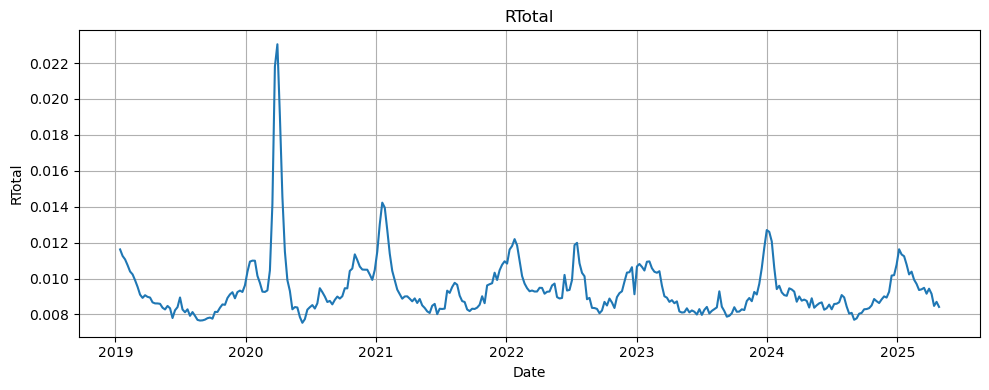

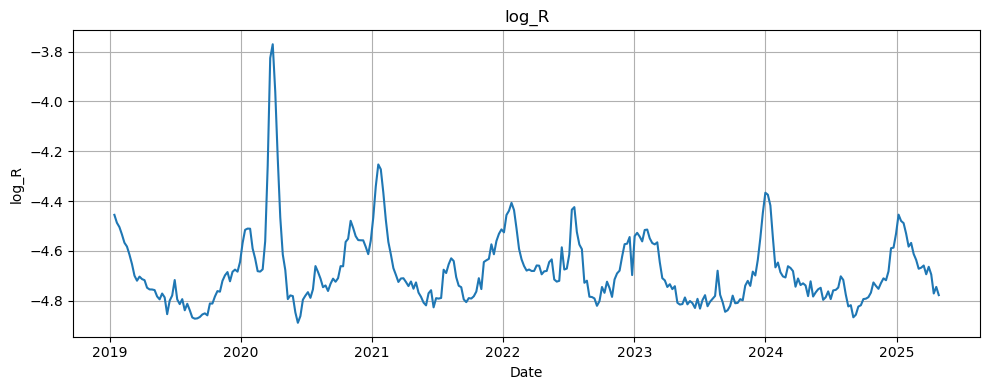

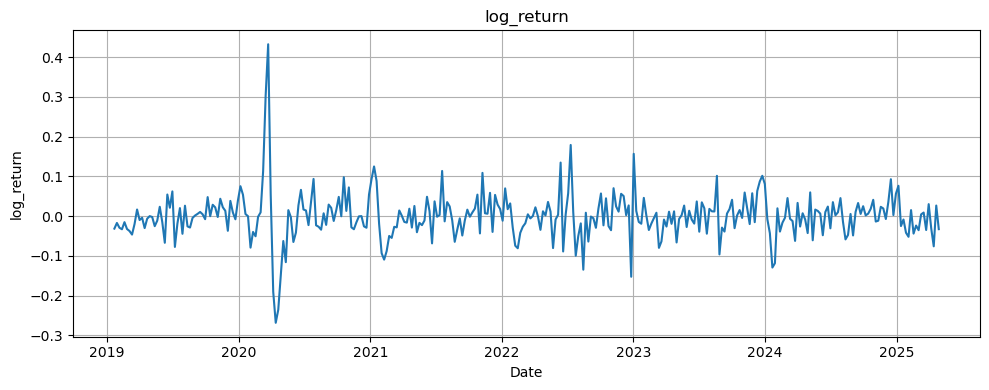

In [16]:
for col in mortality_df.columns:
    if col != 'date':
        plt.figure(figsize=(10, 4))
        plt.plot(mortality_df['date'], mortality_df[col])
        plt.title(col)
        plt.xlabel('Date')
        plt.ylabel(col)
        plt.grid(True)
        plt.tight_layout()
        plt.show()


<Figure size 800x400 with 0 Axes>

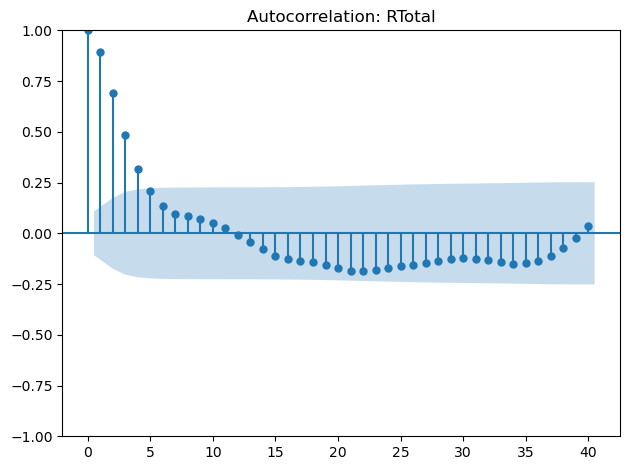

<Figure size 800x400 with 0 Axes>

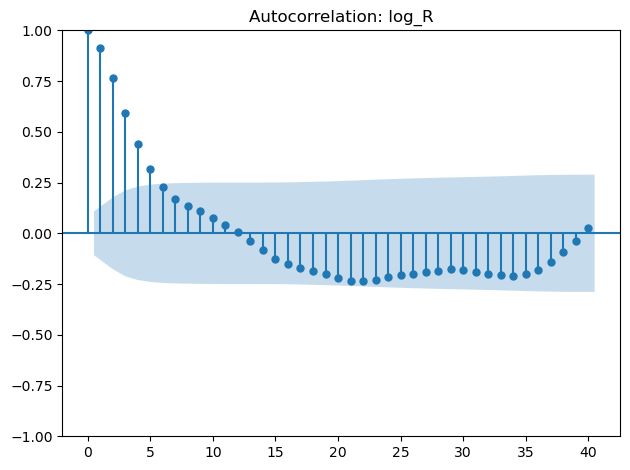

<Figure size 800x400 with 0 Axes>

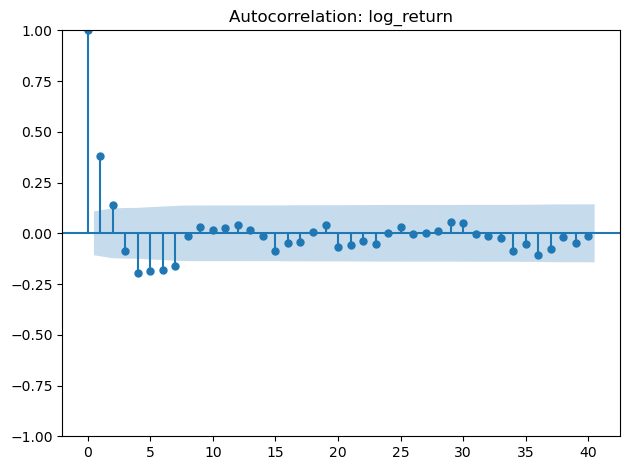

In [17]:
for col in mortality_df.columns:
    if col != 'date':
        plt.figure(figsize=(8, 4))
        plot_acf(mortality_df[col].dropna(), lags=40)
        plt.title(f"Autocorrelation: {col}")
        plt.tight_layout()
        plt.show()


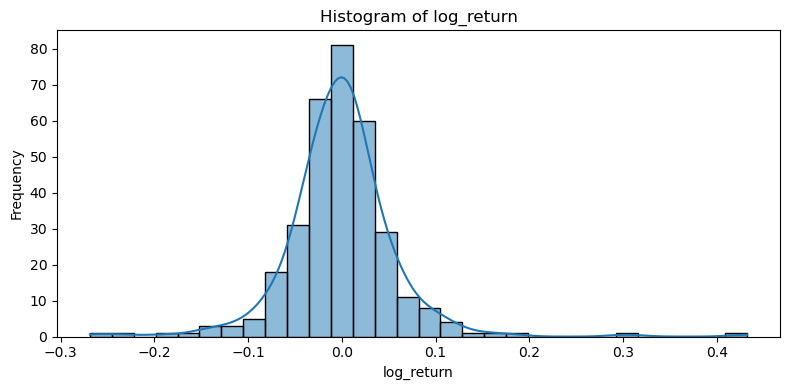

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(mortality_df['log_return'].dropna(), bins=30, kde=True)
plt.title("Histogram of log_return")
plt.xlabel("log_return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [19]:
catbond_df = pd.read_csv("CATBond_pricing.csv")


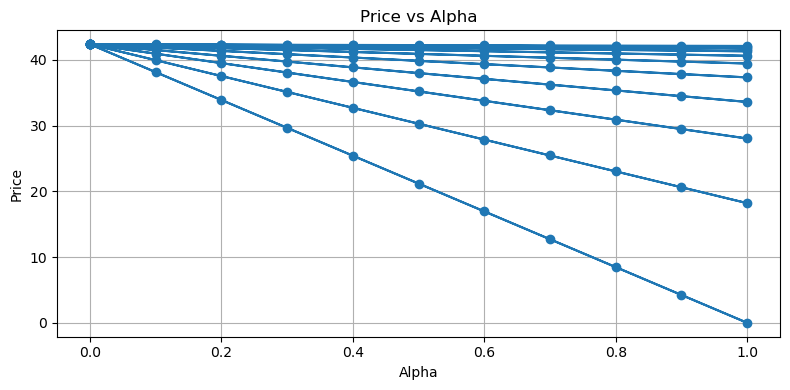

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(catbond_df['alpha'], catbond_df['price'], marker='o')
plt.title("Price vs Alpha")
plt.xlabel("Alpha")
plt.ylabel("Price")
plt.grid(True)
plt.tight_layout()
plt.show()


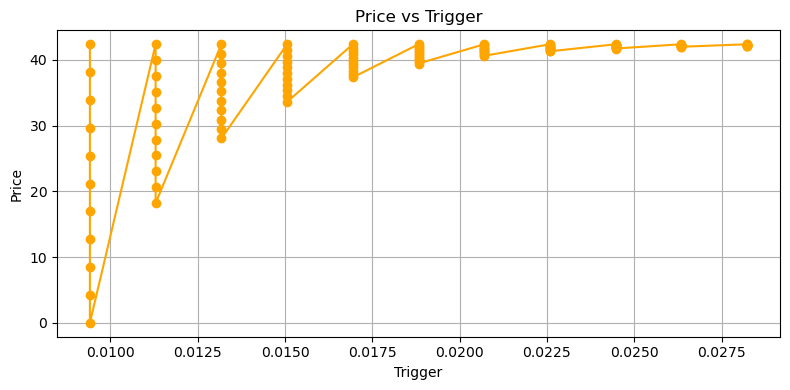

In [21]:
plt.figure(figsize=(8, 4))
plt.plot(catbond_df['trigger'], catbond_df['price'], marker='o', color='orange')
plt.title("Price vs Trigger")
plt.xlabel("Trigger")
plt.ylabel("Price")
plt.grid(True)
plt.tight_layout()
plt.show()


In [22]:
fig = go.Figure(data=[go.Scatter3d(
    x=catbond_df['alpha'],
    y=catbond_df['trigger'],
    z=catbond_df['price'],
    mode='markers',
    marker=dict(size=5, color=catbond_df['price'], colorscale='Viridis')
)])

fig.update_layout(
    title='3D Plot: Price vs Alpha and Trigger',
    scene=dict(
        xaxis_title='Alpha',
        yaxis_title='Trigger',
        zaxis_title='Price'
    )
)

fig.show()
